In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch


pd.set_option('display.max_columns', None)

file = '/Users/jonzimmerman/Desktop/Data Projects/ABS Challenge/data/challenge_data_2026_reg.csv'
df = pd.read_csv(file)
print(df.shape)

(10557, 30)


In [2]:
df.head(2)

,Play ID,Date,Player,Role,Team,Opp,Team Score,Opp Score,Inn,Balls,Strikes,Outs,Runners,Challenges Remaining,Call,Result,Net RE,Net WPA,Dist (in.),xChall%,Call LI,cBE%,acBE%,xStr%,Opp Cost RE,Opp Cost WPA,Potential Run Expectancy delta if overturned,Potential Win Probability Added if overturned,Runs Over Expected,Wins Over Expected
0,2ff576ef-65e7-380a-be70-d68eae4c7501,2026-09-27,Brady House,batter,WSH,NYM,3,4,3,2,1,0,Empty,2,Called Strike,True,0.1760,0.020800,-2.39,0.366641,1.37,0.5064,0.0000,0.070886,0.0000,0.000000,0.176,0.0208,0.111471,0.013174
1,e488118c-2162-35be-809f-055cb4feb9cf,2026-09-27,Marcus Semien,batter,NYM,WSH,4,2,3,0,0,1,1B,1,Called Strike,False,-0.1101,-0.009716,2.27,0.012606,0.44,0.6686,0.5511,0.932469,0.1101,0.009716,0.090,0.0067,-0.108712,-0.009594


### Glossary

- **Net RE**: Net run expectancy impact. Potential RE delta if overturned, or negative opportunity cost if upheld
- **Net win probability impact**: Potential WPA delta if overturned, or negative opportunity cost (WPA) if upheld
- **Dist (in)**: Signed distance from the ball's edge to the nearest zone edge at midplate, in inches
- **xChall%**: Model-predicted probability that a given pitch would be challenged
- **Call LI**: Leverage of the pitch, limited to the ball/strike outcome. 1.0 = average; 2.0 = twice as impactful
- **cBE%**: Unadjusted challenge breakeven %. The minimum probability of overturn needed to justify a challenge, based on the run expectancy swing for this count/base-out state. Does not account for opportunity cost or game timing
- **acBE%**: Breakeven threshold adjusted for opportunity cost and game timing
- **xStr%**: Model-predicted probability the pitch would be called a strike by an average umpire
- **Opp Cost RE**: Expected RE lost from using a challenge here, accounting for the cost of future opportunities
- **Opp Cost WPA**: Expected win probability lost from using a challenge here, sensitive to score and inning
- **pRE**: Potential run expectancy delta if overturned
- **pWPA**: Potential win probability added if overturned
- **ROE**: Runs over expected
- **WOE**: Wins over expected

In [3]:
conditions = [
    (df['Call'] == "Called Strike") & df['Result'],
    (df['Call'] == "Called Strike") & ~df['Result'],
    (df['Call'] == "Ball") & df['Result'],
    (df['Call'] == "Ball") & ~df['Result'],
]

choices = [
    "Ball",
    "Strike",
    "Strike",
    "Ball",
]

df['Updated Call'] = np.select(conditions, choices, default=df['Call'])
col = df.pop('Updated Call')
df.insert(15, 'Updated Call', col)

In [4]:
al = ['ATH', 'BAL', 'BOS', 'CWS', 'CLE', 
      'DET', 'HOU', 'KC',  'LAA', 'MIN', 
      'NYY', 'SEA', 'TEX', 'TOR', 'TB'
] 

nl = ['AZ',  'ATL', 'CHC', 'CIN', 'COL', 
      'LAD', 'MIA', 'MIL', 'NYM', 'PHI', 
      'PIT', 'SD',  'SF',  'STL', 'WSH'
]

league_map = {t: 'AL' for t in al} | {t: 'NL' for t in nl}

df['League'] = df['Team'].map(league_map)
league_colors = {'AL': 'crimson', 'NL': 'royalblue'}


### Challenge EDA

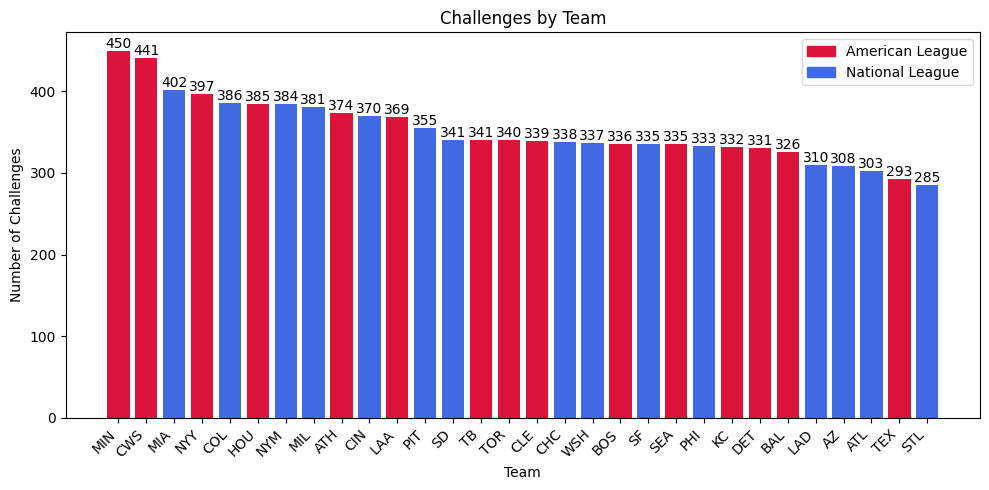

In [5]:
total_counts = df['Team'].value_counts()
colors = [league_colors[league_map[t]] for t in total_counts.index]

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(total_counts.index, total_counts.values, color=colors)
ax.bar_label(ax.containers[0])
ax.set_title('Challenges by Team')
ax.set_xlabel('Team')
ax.set_ylabel('Number of Challenges')
ax.legend(handles=[Patch(color='crimson', label='American League'),
                   Patch(color='royalblue', label='National League')])
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

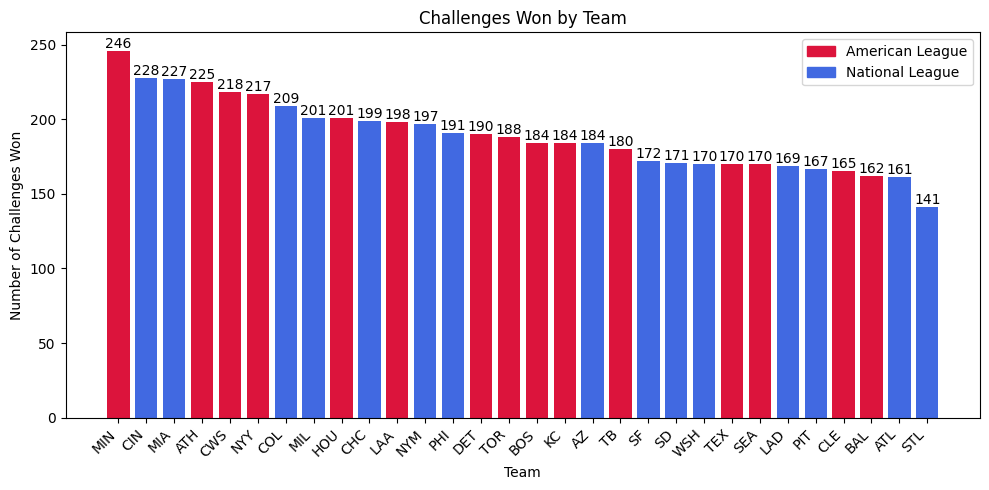

In [6]:
challenge1 = df[['Team','Result']]
challenge1 = challenge1[challenge1['Result']==True]['Team'].value_counts()
colors = [league_colors[league_map[t]] for t in challenge1.index]

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(challenge1.index, challenge1.values, color=colors)

ax.bar_label(ax.containers[0])
ax.set_title('Challenges Won by Team')
ax.set_xlabel('Team')
ax.set_ylabel('Number of Challenges Won')
ax.legend(handles=[Patch(color='crimson', label='American League'),
                   Patch(color='royalblue', label='National League')])
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

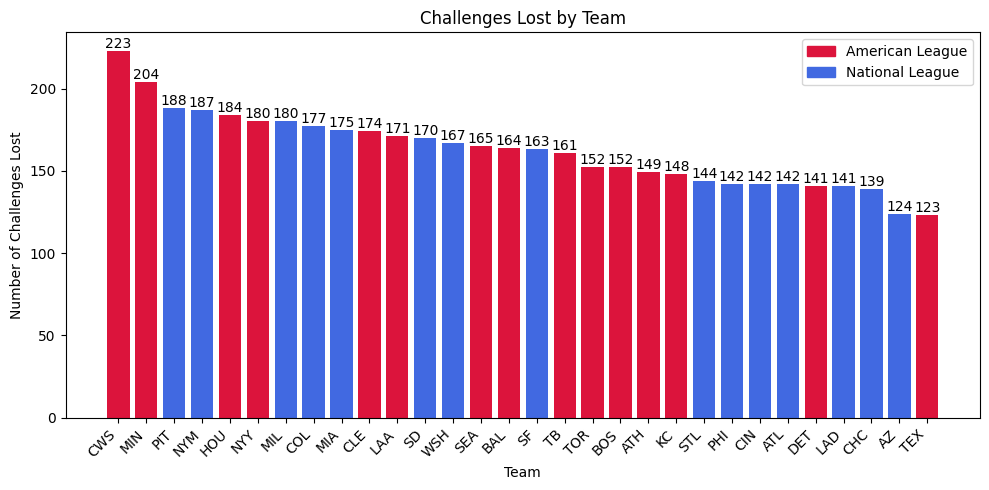

In [7]:
challenge2 = df[['Team','Result']]
challenge2 = challenge2[challenge2['Result']==False]['Team'].value_counts()
colors = [league_colors[league_map[t]] for t in challenge2.index]

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(challenge2.index, challenge2.values, color=colors)
ax.bar_label(ax.containers[0])
ax.set_title('Challenges Lost by Team')
ax.set_xlabel('Team')
ax.set_ylabel('Number of Challenges Lost')
ax.legend(handles=[Patch(color='crimson', label='American League'),
                   Patch(color='royalblue', label='National League')])
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [8]:
challenge = df[['Team','Result']].value_counts().reset_index()
table = challenge.pivot(index='Team', columns='Result', values='count').fillna(0).astype(int)
table = table.rename(columns={True: 'wins', False: 'losses'})
table['total'] = table['wins'] + table['losses']
table['win_pct'] = (table['wins'] / table['total'] * 100).round(1)
table.head()

Result,losses,wins,total,win_pct
Team,,,,
ATH,149,225,374,60.2
ATL,142,161,303,53.1
AZ,124,184,308,59.7
BAL,164,162,326,49.7
BOS,152,184,336,54.8


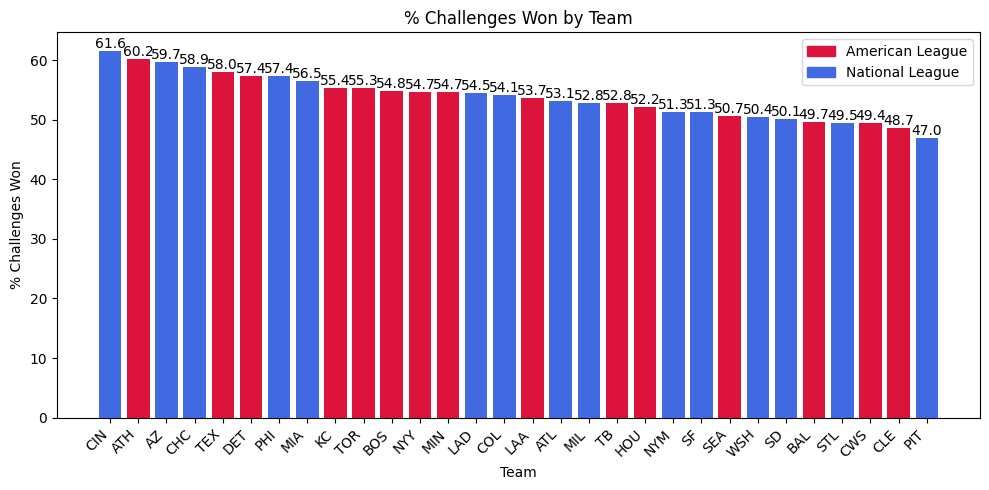

In [9]:
win_table = table.reset_index().sort_values('win_pct', ascending=False)
win_table['League'] = win_table['Team'].map(league_map)
win_pct = win_table[['Team', 'League', 'win_pct']]

colors = win_pct['Team'].map(league_map).map(league_colors)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(win_pct['Team'], win_pct['win_pct'], color=colors)
ax.bar_label(ax.containers[0], fmt='%.1f')
ax.set_title('% Challenges Won by Team')
ax.set_xlabel('Team')
ax.set_ylabel('% Challenges Won')
ax.legend(handles=[Patch(color='crimson', label='American League'),
                   Patch(color='royalblue', label='National League')])
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


### Who's the best challenger?

In [10]:
pos_challenge = df[['Role','Result']].value_counts().reset_index()
pos_table = pos_challenge.pivot(index='Role', columns='Result', values='count').fillna(0).astype(int)
pos_table = pos_table.rename(columns={True: 'wins', False: 'losses'})
pos_table['total'] = pos_table['wins'] + pos_table['losses']
pos_table['win_pct'] = (pos_table['wins'] / pos_table['total'] * 100).round(1)
pos_table.head()

Result,losses,wins,total,win_pct
Role,,,,
batter,2438,2327,4765,48.8
catcher,2326,3286,5612,58.6
pitcher,108,72,180,40.0


In [11]:
def challenge_result_table(challenger, filter_level):

    position = df[df['Role']==challenger]
    challenge = position[['Player','Result']].value_counts().reset_index()
    table = challenge.pivot(index='Player', columns='Result', values='count').fillna(0).astype(int)
    table = table.rename(columns={True: 'wins', False: 'losses'})
    table['total'] = table['wins'] + table['losses']
    table['win_pct'] = (table['wins'] / table['total'] * 100).round(1)

    team_lookup = position.sort_values('Date').groupby('Player')['Team'].last()
    table.insert(0, 'Team', table.index.map(team_lookup))

    table = table[table['total']>=filter_level].sort_values(by = 'win_pct', ascending = False)

    return table


In [12]:
challenge_result_table('batter', 10)

Result,Team,losses,wins,total,win_pct
Player,,,,,
CJ Abrams,WSH,2,12,14,85.7
Cedric Mullins,TB,2,11,13,84.6
Davis Schneider,TOR,3,14,17,82.4
Nick Kurtz,ATH,2,9,11,81.8
Zack Gelof,ATH,4,11,15,73.3
...,...,...,...,...,...
Nasim Nuñez,WSH,9,3,12,25.0
Ceddanne Rafaela,BOS,18,6,24,25.0
Justin Crawford,PHI,10,3,13,23.1


In [13]:
challenge_result_table('catcher', 10)

Result,Team,losses,wins,total,win_pct
Player,,,,,
Adrian Del Castillo,AZ,1,9,10,90.0
P.J. Higgins,CIN,2,9,11,81.8
J.T. Realmuto,PHI,16,70,86,81.4
Sandy León,ATL,5,16,21,76.2
Mitch Garver,SEA,9,25,34,73.5
...,...,...,...,...,...
Yohel Pozo,BAL,8,6,14,42.9
Ali Sánchez,NYY,26,19,45,42.2
Endy Rodríguez,PIT,13,9,22,40.9


In [14]:
challenge_result_table('pitcher', 5)

Result,Team,losses,wins,total,win_pct
Player,,,,,
Drew Anderson,DET,3,5,8,62.5
Freddy Peralta,TB,4,4,8,50.0
Hogan Harris,ATH,3,2,5,40.0
Shane Baz,BAL,3,2,5,40.0
Gregory Soto,PIT,4,2,6,33.3
George Kirby,SEA,4,1,5,20.0
Cristopher Sánchez,PHI,5,0,5,0.0
